### Exploration of how big should the central window be

seed: 779


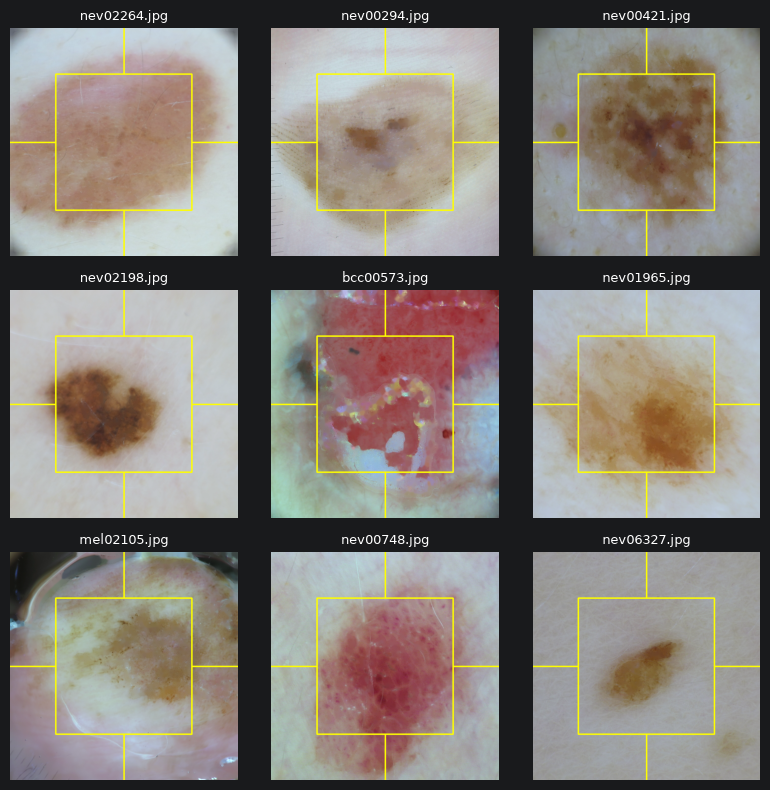

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from src.config import *
from src.utils import *
from src.feature_extraction import draw_regions, extract_extra_features

gt = pd.read_csv(BINARY_GT_TRAIN_SUBSET_CSV)
s = random_sample(gt)
show_grid([draw_regions(load_preprocessed(r.filename, r.label, BINARY_PREPROC_TRAIN_DIR)) for r in s.itertuples()],
          [r.filename for r in s.itertuples()])

In [2]:
r = s.iloc[0]
f = extract_extra_features(load_preprocessed(r.filename, r.label, BINARY_PREPROC_TRAIN_DIR))
print(len(f), "features |", sum(k.startswith("reg_") for k in f), "regional |", sum(k.startswith("hog_") for k in f), "HoG")
pd.Series({k: v for k, v in f.items() if "asym" in k}).round(3)

536 features | 212 regional | 324 HoG


reg_asym_lab_max     13.551
reg_asym_lab_min      7.542
reg_asym_hist_max     0.284
reg_asym_hist_min     0.146
reg_asym_lbp_max      0.013
reg_asym_lbp_min      0.005
reg_asym_glcm_max     0.049
reg_asym_glcm_min     0.017
dtype: float64

In [3]:
import cv2
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops

def lesion_side(img):
    """Rough lesion size: largest side of the bounding box of the dark (Otsu) region, as a fraction of the width."""
    L = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[:, :, 0], (15, 15), 0)
    regions = regionprops(label(L < threshold_otsu(L)))
    if not regions:
        return np.nan
    r0, c0, r1, c1 = max(regions, key=lambda r: r.area).bbox
    return max(r1 - r0, c1 - c0) / L.shape[1]

sample = pd.read_csv(BINARY_GT_TRAIN_SUBSET_CSV).sample(500, random_state=RANDOM_STATE)
sample["side"] = [lesion_side(load_preprocessed(r.filename, r.label, BINARY_PREPROC_TRAIN_DIR))
                  for r in sample.itertuples()]
sample.groupby("label")["side"].describe(percentiles=[0.25, 0.5, 0.75]).round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,237.0,0.64,0.25,0.11,0.44,0.64,0.88,1.0
1,263.0,0.74,0.23,0.07,0.56,0.76,0.98,1.0


The medians of both groups lie around 0.6-0.7 so we will take 60% (0.6) of the image width as the side of the central squared region.

### Check after obtaining the new features on all the images

In [4]:
from src.feature_extraction import extract_features

full = pd.read_csv(BINARY_FEATURES_TRAIN_FULL_CSV)
subset_files = set(pd.read_csv(BINARY_GT_TRAIN_SUBSET_CSV)["filename"])
check = full[~full["filename"].isin(subset_files)].sample(5, random_state=RANDOM_STATE)

for r in check.itertuples(index=False):
    new = pd.Series(extract_features(load_preprocessed(r.filename, r.label, BINARY_PREPROC_TRAIN_DIR)))
    old = pd.Series(r._asdict()).drop(["filename", "label"]).astype(float)
    print(f"{r.filename}: max abs diff = {(new - old[new.index]).abs().max():.2e}")

nev04949.jpg: max abs diff = 2.84e-14
mel01542.jpg: max abs diff = 2.84e-14
bcc00507.jpg: max abs diff = 7.11e-15
nev01744.jpg: max abs diff = 7.11e-15
mel01165.jpg: max abs diff = 7.11e-15


Since the differences are small, we can say that the feature extraction was good and consistent with what we had defined previuly, so the original 232 features are the same.

### Studying each group of features

In [5]:
from sklearn.model_selection import cross_validate
from src.experiments import run_experiment, show, CV, BINARY_SCORING

base = pd.read_csv(BINARY_FEATURES_TRAIN_FULL_CSV)
extra = pd.read_csv(BINARY_EXTRA_TRAIN_FULL_CSV)
assert (base["filename"] == extra["filename"]).all()          # same row order -> same CV folds as exp6
data = base.merge(extra.drop(columns="label"), on="filename")
y = data["label"].values

base_cols = [c for c in base.columns if c not in ("filename", "label")]
reg_cols = [c for c in extra.columns if c.startswith("reg_")]
hog_cols = [c for c in extra.columns if c.startswith("hog_")]

FEATURE_SETS = {
    "F0 base": base_cols,
    "F1 base + regional": base_cols + reg_cols,
    "F2 base + HoG": base_cols + hog_cols,
    "F3 all": base_cols + reg_cols + hog_cols,
}
{name: len(cols) for name, cols in FEATURE_SETS.items()}

{'F0 base': 230,
 'F1 base + regional': 442,
 'F2 base + HoG': 554,
 'F3 all': 766}

In [6]:
RESULTS_CSV = RESULTS_DIR / "exp7_new_features.csv"
FOLDS_CSV = RESULTS_DIR / "exp7_new_features_folds.csv"
tables, folds, fitted = [], [], {}

for name, cols in FEATURE_SETS.items():
    X = data[cols].values
    table, fit = run_experiment(name, X, y, only=["SVM (RBF)"])
    fitted[name] = fit["SVM (RBF)"]
    # per-fold scores of the best configuration, for the paired comparison with F0
    scores = cross_validate(fitted[name], X, y, cv=CV, scoring=BINARY_SCORING, n_jobs=-2)
    folds.append(pd.DataFrame({m: scores[f"test_{m}"] for m in BINARY_SCORING}).assign(experiment=name, fold=range(5)))
    tables.append(table)
    pd.concat(tables, ignore_index=True).to_csv(RESULTS_CSV, index=False)
    pd.concat(folds, ignore_index=True).to_csv(FOLDS_CSV, index=False)

show(pd.concat(tables, ignore_index=True))

[F0 base] SVM (RBF): balanced_accuracy = 0.831
[F1 base + regional] SVM (RBF): balanced_accuracy = 0.847
[F2 base + HoG] SVM (RBF): balanced_accuracy = 0.826
[F3 all] SVM (RBF): balanced_accuracy = 0.842


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,F0 base,SVM (RBF),0.831 ± 0.007,0.831 ± 0.007,0.827 ± 0.015,0.835 ± 0.007,0.907 ± 0.008
1,F1 base + regional,SVM (RBF),0.848 ± 0.004,0.847 ± 0.004,0.841 ± 0.007,0.854 ± 0.003,0.921 ± 0.006
2,F2 base + HoG,SVM (RBF),0.827 ± 0.003,0.826 ± 0.003,0.810 ± 0.009,0.843 ± 0.004,0.902 ± 0.004
3,F3 all,SVM (RBF),0.842 ± 0.005,0.842 ± 0.004,0.822 ± 0.007,0.861 ± 0.009,0.917 ± 0.005


In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RandomizedSearchCV
from src.experiments import build_models, search_space, N_ITER

name, cols = "F4 all + SelectKBest", FEATURE_SETS["F3 all"]
X = data[cols].values
space = {**search_space("SVM (RBF)"), "select__k": [100, 200, 300, 400, "all"]}
search = RandomizedSearchCV(build_models(selector=SelectKBest(f_classif))["SVM (RBF)"], space,
                            n_iter=N_ITER["SVM (RBF)"], cv=CV, scoring=BINARY_SCORING,
                            refit="balanced_accuracy", n_jobs=-2, random_state=RANDOM_STATE)
search.fit(X, y)
fitted[name], i, res = search.best_estimator_, search.best_index_, search.cv_results_

folds.append(pd.DataFrame({m: [res[f"split{f}_test_{m}"][i] for f in range(5)] for m in BINARY_SCORING})
             .assign(experiment=name, fold=range(5)))
tables.append(pd.DataFrame([{"experiment": name, "model": "SVM (RBF)",
                             **{m: res[f"mean_test_{m}"][i] for m in BINARY_SCORING},
                             **{f"{m}_std": res[f"std_test_{m}"][i] for m in BINARY_SCORING},
                             "params": search.best_params_}]))
pd.concat(tables, ignore_index=True).to_csv(RESULTS_CSV, index=False)
pd.concat(folds, ignore_index=True).to_csv(FOLDS_CSV, index=False)
show(pd.concat(tables, ignore_index=True))

,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,F0 base,SVM (RBF),0.831 ± 0.007,0.831 ± 0.007,0.827 ± 0.015,0.835 ± 0.007,0.907 ± 0.008
1,F1 base + regional,SVM (RBF),0.848 ± 0.004,0.847 ± 0.004,0.841 ± 0.007,0.854 ± 0.003,0.921 ± 0.006
2,F2 base + HoG,SVM (RBF),0.827 ± 0.003,0.826 ± 0.003,0.810 ± 0.009,0.843 ± 0.004,0.902 ± 0.004
3,F3 all,SVM (RBF),0.842 ± 0.005,0.842 ± 0.004,0.822 ± 0.007,0.861 ± 0.009,0.917 ± 0.005
4,F4 all + SelectKBest,SVM (RBF),0.840 ± 0.005,0.840 ± 0.005,0.824 ± 0.011,0.856 ± 0.004,0.916 ± 0.004


In [8]:
r = pd.DataFrame(res)
print("Best balanced accuracy per k:")
display(r.groupby(r["param_select__k"].astype(str))["mean_test_balanced_accuracy"].max().round(3))

selected = np.array(cols)[fitted[name].named_steps["select"].get_support()]
print("Selected features per group:")
pd.Series(["base" if c in base_cols else c.split("_")[0] for c in selected]).value_counts()

Best balanced accuracy per k:


param_select__k
100    0.824
200    0.836
300    0.840
400    0.835
all    0.825
Name: mean_test_balanced_accuracy, dtype: float64

Selected features per group:


base    113
hog      95
reg      92
Name: count, dtype: int64

In [9]:
ba = pd.concat(folds).pivot(index="fold", columns="experiment", values="balanced_accuracy")
gain = ba.sub(ba["F0 base"], axis=0).drop(columns="F0 base")
pd.DataFrame({"mean gain": gain.mean(), "std": gain.std(), "folds won": (gain > 0).sum()}).round(3)

,mean gain,std,folds won
experiment,,,
F1 base + regional,0.017,0.006,5
F2 base + HoG,-0.004,0.008,2
F3 all,0.011,0.006,5
F4 all + SelectKBest,0.009,0.007,5


### Comparing SVM vs Stacking ensemble: Base + regional features (F1) on the full train dataset.

In [10]:
import time
from sklearn.base import clone
from src.experiments import build_ensembles

cols = FEATURE_SETS["F1 base + regional"]
X = data[cols].values

# SVM: tuned on F1 (exp7). Trees: exp5 hyperparameters (not re-tuned)
BASE = ["HistGradBoost", "SVM (RBF)", "XGBoost", "CatBoost"]
exp5 = pd.read_csv(RESULTS_DIR / "exp5_binary_ensembles.csv")
exp7 = pd.read_csv(RESULTS_DIR / "exp7_new_features.csv").set_index("experiment")
params = {r.model: eval(r.params, {"np": np}) for r in exp5.itertuples() if r.model in BASE}
params["SVM (RBF)"] = eval(exp7.loc["F1 base + regional", "params"], {"np": np})
print(params["SVM (RBF)"])

all_models = build_models()
base_models = {n: clone(all_models[n]).set_params(**params[n]) for n in BASE}
stacking = build_ensembles(base_models)["Stacking (LogReg)"]

start = time.perf_counter()
scores = cross_validate(stacking, X, y, cv=CV, scoring=BINARY_SCORING, n_jobs=5)   # one fold per core
print(f"{(time.perf_counter() - start) / 60:.0f} min")

stack_folds = pd.DataFrame({m: scores[f"test_{m}"] for m in BINARY_SCORING}).assign(
    experiment="F1 stacking", fold=range(5))
stack_folds.to_csv(RESULTS_DIR / "exp8_f1_stacking_folds.csv", index=False)

{'clf__C': np.float64(11.290133559092672), 'clf__gamma': np.float64(0.0020914981329035616)}
36 min


In [11]:
metrics = list(BINARY_SCORING)
svm_folds = pd.read_csv(FOLDS_CSV).query("experiment == 'F1 base + regional'").reset_index(drop=True)

display(pd.DataFrame({"SVM (F1)": svm_folds[metrics].mean(),
                      "Stacking (F1)": stack_folds[metrics].mean()}).T.round(3))

d = stack_folds["balanced_accuracy"] - svm_folds["balanced_accuracy"]
print(f"stacking - SVM = {d.mean():.3f} ± {d.std():.3f}  (folds won: {(d > 0).sum()}/5)")

,accuracy,balanced_accuracy,sensitivity,specificity,auc
SVM (F1),0.848,0.847,0.841,0.854,0.921
Stacking (F1),0.852,0.852,0.844,0.859,0.928


stacking - SVM = 0.004 ± 0.004  (folds won: 4/5)


This tells us that the stacking ensemble is a better fit for solving the task. With this information, let's train the ensemble using the whole dataset.

In [12]:
import joblib

final_name = "Stacking (F1)"
final = clone(stacking).set_params(n_jobs=4)          # the 4 base models train in parallel
start = time.perf_counter()
final.fit(X, y)
print(f"{(time.perf_counter() - start) / 60:.0f} min")
joblib.dump({"model": final, "features": cols}, MODELS_DIR / "binary_final_stacking_f1.joblib")

13 min


['C:\\Users\\ferra\\MIC\\2n_any_UdG\\CADx\\Project\\Project-1-CAD\\models\\binary_final_stacking_f1.joblib']

Now it's time to see if the best model we could find performs well in the validation set. This is our first time opening this set for evaluation to prevent overfitting to this set.

,accuracy,balanced_accuracy,sensitivity,specificity,auc
CV (train),0.852,0.852,0.844,0.859,0.928
validation,0.863,0.863,0.858,0.868,0.932


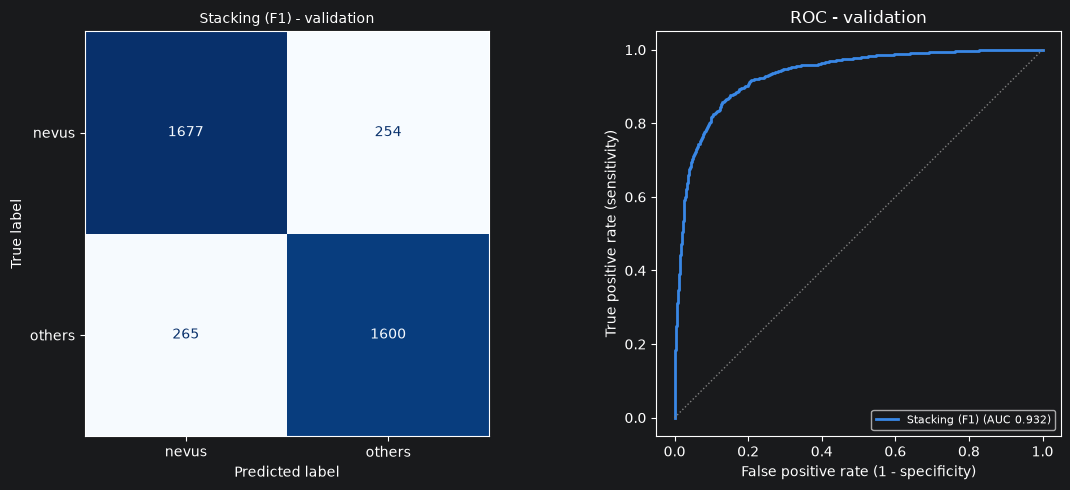

In [13]:
import matplotlib.pyplot as plt
from src.experiments import evaluate

val = pd.read_csv(BINARY_FEATURES_VAL_CSV).merge(
    pd.read_csv(BINARY_EXTRA_VAL_CSV).drop(columns="label"), on="filename")
X_val, y_val = val[cols].values, val["label"].values

display(pd.DataFrame({"CV (train)": stack_folds[metrics].mean(),
                      "validation": pd.Series(evaluate(final, X_val, y_val))}).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_confusion(axes[0], y_val, final.predict(X_val), f"{final_name} - validation")
plot_roc(axes[1], y_val, final.decision_function(X_val), final_name, "#3987e5")
finish_roc(axes[1], "ROC - validation")
plt.tight_layout()
plt.show()

Let's build a summary of the results:

In [14]:
pd.DataFrame([{"model": final_name, "features": "base + regional (442)", "train_images": len(y),
               **evaluate(final, X_val, y_val)}]).to_csv(RESULTS_DIR / "final_binary_validation.csv", index=False)